# 03b - Predator-Prey: the predator that wanders off

Same game as notebook 03: 3 predators chase 1 faster prey; the prey is frozen for the first 0.5M training steps, then learns.

Look at the **predators' reward** again: every step, **+10 for each predator touching the prey - and every predator gets it**.
* A predator gets the same reward whether it caught the prey itself, helped corner it, or was somewhere else entirely.
* Predators are **not** penalised for leaving the arena (only the prey is).

So each predator has to work out from a *shared* number whether *its own* action helped. This is the **credit-assignment problem**.
If it goes wrong, an agent can stop contributing and still collect the team's reward - a **lazy agent**.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from marl.analysis import *
from marl.render import show_video
plt.rcParams["figure.dpi"] = 90
COL = {"maddpg": "tab:blue", "facvdn": "tab:orange", "facqmix": "tab:green"}

## 1. MADDPG: one predator leaves

Trained MADDPG predators (2M steps) in three episodes, seen from above. Circles = start, crosses = end, dashed square = arena.

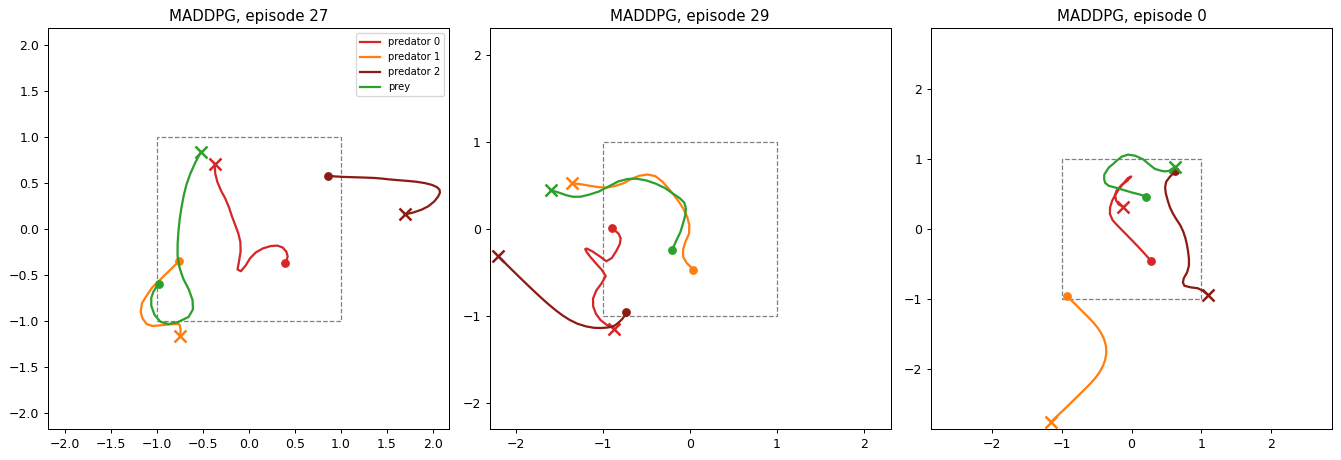

In [2]:
maddpg = tag_seed_runs("maddpg")
pol_m = snapshot(maddpg[0], 2_000_000)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, ep in zip(ax, (27, 29, 0)):
    plot_tag_paths(pol_m, seed=ep, ax=a, title=f"MADDPG, episode {ep}")
ax[0].legend(fontsize=8)
plt.tight_layout()

Two predators chase the prey; the third runs off the map **away from the prey** and never comes back.

In [3]:
show_video(video(pol_m, "tag", {}, seed=27, title="MADDPG predators (2M steps)"))

### Is it really doing nothing?
Measured over 128 episodes per predator: touches of the prey, time off the arena, and time **off the arena while the prey is more than
1.0 away** (not chasing it).

Then a counterfactual: freeze one predator in place and count how many touches the team loses. A predator whose absence costs nothing
contributes nothing.

In [4]:
st = predator_stats(pol_m, episodes=128)
full, loss = predator_contributions(pol_m, episodes=128)
print("predator   touches/ep   off arena   off & far from prey   team loses if frozen")
for i in range(3):
    print(f"{i:>8}   {st['touches'][i]:10.2f}   {st['off_arena'][i]:9.2f}   {st['off_far'][i]:19.2f}   {loss[i]:20.2f}")
print(f"team touches/ep with all three: {full:.2f}")

predator   touches/ep   off arena   off & far from prey   team loses if frozen
       0         0.60        0.07                  0.03                   0.57
       1         0.24        0.23                  0.19                   0.30
       2         0.18        0.31                  0.26                   0.00
team touches/ep with all three: 1.02


Is it just this run? The same measures on every snapshot of all **3 seeds** (line = mean over seeds, band = min-max).
The grey line marks where the prey starts learning.

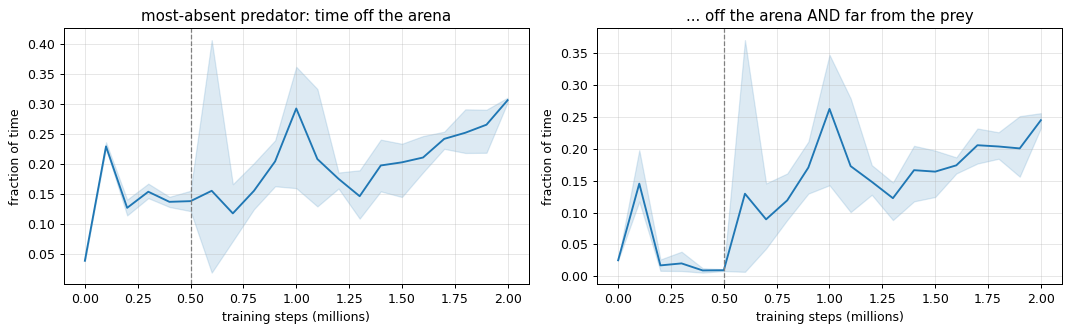

In [5]:
summary = load_tag_credit_summary()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_tag_credit({"maddpg": summary["maddpg"]}, "max_off_arena", ax[0], colors=COL,
                title="most-absent predator: time off the arena", ylabel="fraction of time")
plot_tag_credit({"maddpg": summary["maddpg"]}, "max_off_far", ax[1], colors=COL,
                title="... off the arena AND far from the prey", ylabel="fraction of time")
plt.tight_layout()

* While the prey is frozen, catching it is easy: all predators pile on and nobody wanders.
* Once the prey learns to run, touches become rare. A rare, shared reward is a weak and noisy signal for each predator about *its own* moves -
  and in every seed one predator drifts away for up to a third of the episode.

Why does MADDPG's critic not prevent this? Each predator's critic Q_i(s, a_1, a_2, a_3) predicts the **team** reward from everything.
When the other two predators are doing the catching, the team value hardly depends on the third predator's action, so its actor
gets almost no gradient - and there is no cost to drifting.

## 2. Factored critics: VDN and QMIX for continuous actions

Value decomposition gives each predator its **own** value, learned from the shared reward (FACMAC-style: keep the DDPG actors, change only the critic):

* each predator *i* has a utility **Q_i(o_i, a_i)** - from its own observation and its own action only;
* **VDN:** Q_tot = Q_1 + Q_2 + Q_3
* **QMIX:** Q_tot = f_s(Q_1, Q_2, Q_3) - a mixing network whose weights (always >= 0) come from small networks that look at the global state s.

Only Q_tot is trained on the team reward. Each actor climbs **dQ_tot / da_i**; for VDN that is exactly **dQ_i / da_i** - a predator is
pushed by the value of *its own* action, not by whatever the team happened to get.
The prey is unchanged (MADDPG critic), so the only difference to section 1 is the predators' critic.

| | MADDPG critic (per predator) | factored critic (team) |
|---|---|---|
| input | all observations + all actions | own observation + own action |
| trained on | team reward | team reward, through Q_tot |
| actor follows | dQ_i(s, a_1..a_3)/da_i | dQ_tot/da_i (VDN: dQ_i(o_i, a_i)/da_i) |

In [6]:
vdn, qmix = tag_seed_runs("facvdn"), tag_seed_runs("facqmix")
print("MADDPG"); describe_networks(maddpg[0])
print("\nFAC-VDN"); describe_networks(vdn[0])
mix = torch.load(qmix[0]["dir"] / "final.pt", weights_only=False)["mixer"]
print(f"\nFAC-QMIX: same networks + a mixing network (hypernetworks of the state): {sum(v.numel() for v in mix.values()):,} parameters")

MADDPG
network                  used by      layers               hidden act.  output                      params
actor                    adversary_0  16 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5573  
actor                    adversary_1  16 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5573  
actor                    adversary_2  16 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5573  
actor                    agent_0      14 -> 64 -> 64 -> 5  ReLU         sigmoid -> action in [0,1]  5445  
critic Q (action value)  adversary_0  82 -> 64 -> 64 -> 1  ReLU         scalar                      9537  
critic Q (action value)  adversary_1  82 -> 64 -> 64 -> 1  ReLU         scalar                      9537  
critic Q (action value)  adversary_2  82 -> 64 -> 64 -> 1  ReLU         scalar                      9537  
critic Q (action value)  agent_0      82 -> 64 -> 64 -> 1  ReLU         scalar                      9537  
total parameters: 60,312

FAC-

*Practical note:* QMIX did not learn at first. Its mixer over-estimated Q_tot by ~70x, so the per-predator utilities carried almost no
signal about actions. Training **two** critics and using the smaller estimate in the target (as in TD3) fixed it; the QMIX runs use that.

## 3. Same episodes, factored critics

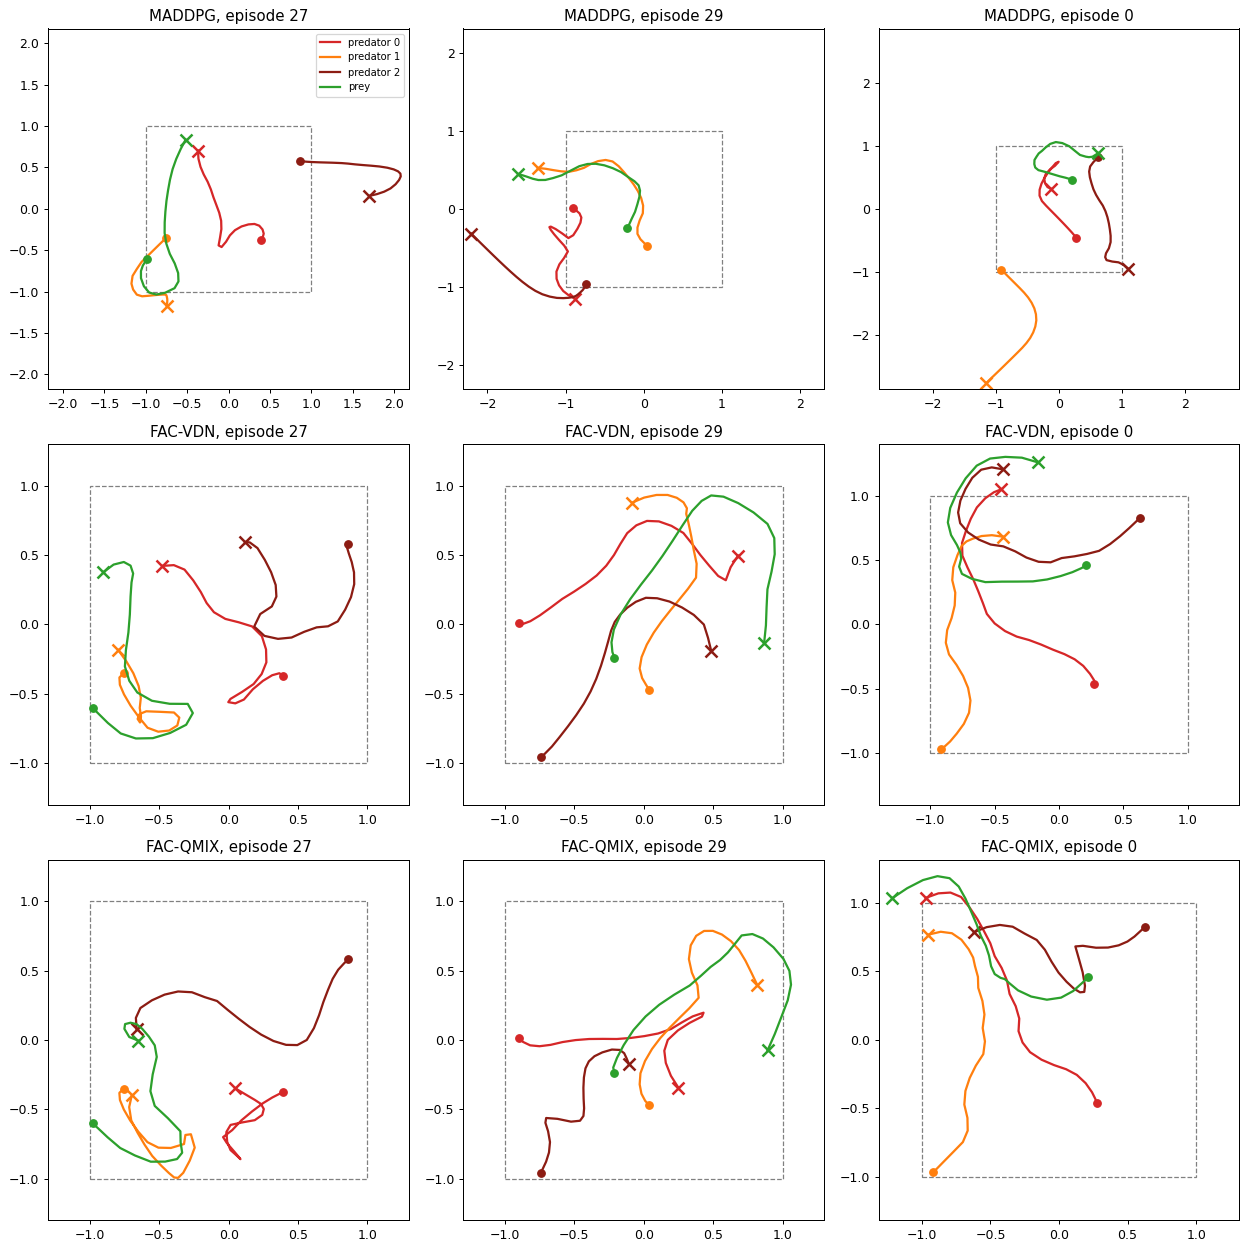

In [7]:
pol_v, pol_q = snapshot(vdn[0], 2_000_000), snapshot(qmix[0], 2_000_000)
fig, ax = plt.subplots(3, 3, figsize=(14, 14))
for r, (pol, name) in enumerate([(pol_m, "MADDPG"), (pol_v, "FAC-VDN"), (pol_q, "FAC-QMIX")]):
    for c, ep in enumerate((27, 29, 0)):
        plot_tag_paths(pol, seed=ep, ax=ax[r, c], title=f"{name}, episode {ep}")
ax[0, 0].legend(fontsize=8)
plt.tight_layout()

In [8]:
show_video(video(pol_m, "tag", {}, seed=27, title="MADDPG") + video(pol_v, "tag", {}, seed=27, title="FAC-VDN")
           + video(pol_q, "tag", {}, seed=27, title="FAC-QMIX"))

Every predator now heads for the prey. Over all seeds and snapshots:

   MADDPG after 0.6M:  off arena 0.21   off & far 0.17   least-involved share 0.24
  FAC-VDN after 0.6M:  off arena 0.09   off & far 0.04   least-involved share 0.25
 FAC-QMIX after 0.6M:  off arena 0.08   off & far 0.04   least-involved share 0.23


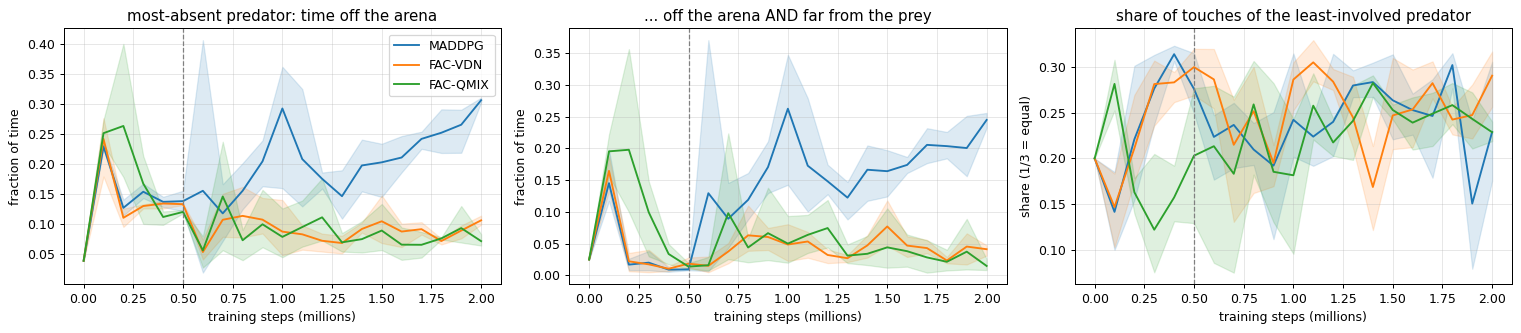

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
plot_tag_credit(summary, "max_off_arena", ax[0], colors=COL, title="most-absent predator: time off the arena", ylabel="fraction of time")
plot_tag_credit(summary, "max_off_far", ax[1], colors=COL, title="... off the arena AND far from the prey", ylabel="fraction of time")
plot_tag_credit(summary, "laziest_share", ax[2], colors=COL, title="share of touches of the least-involved predator", ylabel="share (1/3 = equal)")
ax[0].legend()
plt.tight_layout()
late = summary["maddpg"]["step"][0] >= 600_000
for algo, d in summary.items():
    print(f"{TAG_CREDIT_ALGOS[algo]:>9} after 0.6M:  off arena {d['max_off_arena'][:, late].mean():.2f}   "
          f"off & far {d['max_off_far'][:, late].mean():.2f}   least-involved share {np.nanmean(d['laziest_share'][:, late]):.2f}")

## 4. Are the factored predators better hunters?

Each team's touches so far were measured against its *own* prey, which also learned differently. For a fair comparison, play the
predators of every algorithm against the prey of every algorithm (all 3 x 3 seed pairs, final snapshots).

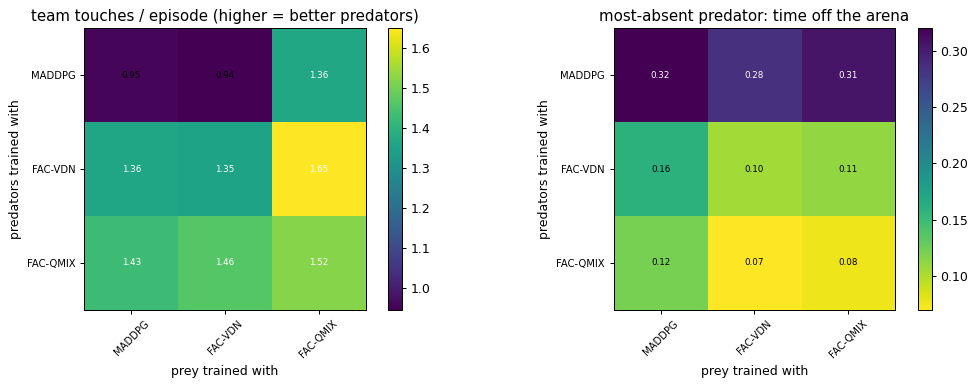

In [10]:
touches, off, names = tag_algo_crossplay(2_000_000, episodes=64)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
plot_matrix(touches, names, ax=ax[0], title="team touches / episode (higher = better predators)", xlabel="prey trained with",
            ylabel="predators trained with", cmap="viridis")
plot_matrix(off, names, ax=ax[1], title="most-absent predator: time off the arena", xlabel="prey trained with",
            ylabel="predators trained with")
plt.tight_layout()

## Takeaways
* **A shared reward hides who did the work.** MADDPG predators developed a predator that leaves the arena and stops chasing - in all
  3 seeds, against every prey - while still receiving the full team reward.
* **Value decomposition** (VDN's sum, QMIX's monotonic mix) gives each agent its own value Q_i(o_i, a_i); with it, the wandering predator
  disappears (3/3 seeds each).
* **Honest caveats:**
  * It is not a "lazy agent" in the strict sense: the wanderer still makes some touches (the least-involved predator's share of touches is
    similar for all three methods).
  * Better behaviour is not automatically more catches: against the same prey, the factored predators catch more at the end of
    training, but MADDPG's caught more at 1M steps (try `tag_algo_crossplay(1_000_000)`).
  * QMIX needed an extra stabiliser (twin critics).
  * While the prey was frozen and catching was easy, no method had a wandering predator: credit assignment bites when the reward becomes rare.
* Next: the same idea on a harder team game - **SMAClite** (notebook 06), where VDN and QMIX were designed.